# Execute the code below

In [41]:
import pandas as pd
import numpy as np
link = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather2019.csv"
df_weather = pd.read_csv(link)

## You have now a DataFrame with lots of weather data

In [42]:
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WINDTEMP_MAX_C,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.0,...,3,116,143,176,0,1,5.1,very bad,1,1
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.0,...,3,119,116,116,0,1,8.7,very bad,1,2
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.0,...,-4,116,116,116,0,1,8.7,very bad,1,3
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.0,...,-4,116,116,122,0,1,5.1,very bad,1,4
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.0,...,-2,143,116,116,0,1,8.7,very bad,1,5


# Now, complete the following tasks :
# Let's go in the deep !

## 1 - Merge
OK, you know very well the previous dataset. Now, you want more, much more. Another year for example ?

But it's too bad. The year 2018 is not in the good  shape. There are 2 files :
- The main file with Temperature, etc...
- The opinion file, with especially the Opinion

The goal is [to merge](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.merge.html) both files in one DataFrame called **df2018**. It seems both files have a date column with the same format (but not the same name).

Think about checking if both datasets have the same length. If they don't, what kind of merge do you have to do to keep each date of the main dataset ? Then apply this specific merge.

In [43]:
link_main = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather_main_2018.csv"
link_opinion = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather_opinion_2018.csv"
df_main = pd.read_csv(link_main)
df_opinion = pd.read_csv(link_opinion)
print(df_main.head())
print(df_opinion.head())

         DATE  MAX_TEMPERATURE_C  MIN_TEMPERATURE_C  WINDSPEED_MAX_KMH  \
0  2018-01-01                 12                  8                 61   
1  2018-01-02                 13                  6                 26   
2  2018-01-03                 15                 10                 40   
3  2018-01-04                 14                 11                 45   
4  2018-01-05                 12                  7                 21   

   TEMPERATURE_MORNING_C  TEMPERATURE_NOON_C  TEMPERATURE_EVENING_C  \
0                      9                  11                      8   
1                      8                  12                     13   
2                     11                  12                     10   
3                     14                  14                     11   
4                     10                  11                      8   

   PRECIP_TOTAL_DAY_MM  HUMIDITY_MAX_PERCENT  VISIBILITY_AVG_KM  \
0                  8.9                    79              9.5

In [44]:
df2018 = pd.merge(df_main, df_opinion, left_on="DATE", right_on="date", how="left")
print(df2018)

           DATE  MAX_TEMPERATURE_C  MIN_TEMPERATURE_C  WINDSPEED_MAX_KMH  \
0    2018-01-01                 12                  8                 61   
1    2018-01-02                 13                  6                 26   
2    2018-01-03                 15                 10                 40   
3    2018-01-04                 14                 11                 45   
4    2018-01-05                 12                  7                 21   
..          ...                ...                ...                ...   
360  2018-12-27                  7                  2                  6   
361  2018-12-28                  7                  2                  8   
362  2018-12-29                  7                  1                  6   
363  2018-12-30                  9                  4                  6   
364  2018-12-31                  9                  5                 10   

     TEMPERATURE_MORNING_C  TEMPERATURE_NOON_C  TEMPERATURE_EVENING_C  \
0             

### Result

Your DataFrame **df2018** should now have 21 columns and 365 rows. If not, try again.

**Be careful:**
- if you've renamed your `date` column, then merged both DataFrames with `on` parameter, Pandas kept only one `DATE` column. So you'll have 20 columns in your DataFrame. And you can skip the "drop" step just after.
- if you merged with `left_on` and `right_on` parameters, Pandas kept both columns `DATE` and `date`, and you'll have 21 columns in your DataFrame. You can do this "drop" step:



In [45]:
# You should now probably drop the "date" column.
# This column is incomplete, it were provided from the opinion file.
# It was very useful to perform the "merge". But we don't need it anymore.

# Read and execute the code below :
df2018.drop('date',             # Select column to drop
            axis = 1,           # Precise if you want to drop a column (1) or a row (0)
            inplace = True)     # If we don't use this argument, result is not stored

C:\Users\steph\AppData\Local\Temp\ipykernel_2716\1884705959.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df2018.drop('date',             # Select column to drop


Now, everybody should have a 20 columns and 365 rows.

**Ohhhh, there are some missing values, we have to fill them. That will be the goal of this quest: to learn how to fill in the missing values, column by column, with different techniques.**

In [46]:
# Just execute the code below, to display a "non-null" column :
print("My DataFrame shape is : ", df2018.shape, end = '\n\n\n\n')
print('Which columns have missing values ? (Non-null column)')
print(df2018.info())



My DataFrame shape is :  (365, 20)



Which columns have missing values ? (Non-null column)
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    str    
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C

### Find and display the Dates of missing values.
You can help you with the method `.isna()`

You have to find 24 different dates.

In [47]:
# Your code here : 

# Objectif : Transformer le tableau de valeur en un tableau de True/False.
missing_values = df2018.isna().any(axis=1)                      # Ensuite, any signifie "au moins un" et axis=1 dit à Pandas de regarder horizontalement (ligne par ligne).
print(missing_values)

# Maintenant, nous souhaitons afficher les valeurs "True", en plus de retourner leurs valeurs initiales, et ceci uniquement pour le tableau df2018.
missing_values = df2018[df2018.isna().any(axis=1)]["DATE"]      # ["DATE"] permet de sélectionner uniquement la colonne qui nous intéresse 
print(missing_values)
print(len(missing_values))

print(missing_values.nunique())     # Permegt d'obtenir le nombre de valeurs uniques.

0      False
1      False
2      False
3      False
4      False
       ...  
360    False
361    False
362    False
363    False
364    False
Length: 365, dtype: bool
18     2018-01-19
31     2018-02-01
66     2018-03-08
100    2018-04-11
118    2018-04-29
143    2018-05-24
152    2018-06-02
163    2018-06-13
165    2018-06-15
175    2018-06-25
184    2018-07-04
191    2018-07-11
194    2018-07-14
197    2018-07-17
204    2018-07-24
220    2018-08-09
225    2018-08-14
234    2018-08-23
266    2018-09-24
317    2018-11-14
321    2018-11-18
325    2018-11-22
346    2018-12-13
349    2018-12-16
Name: DATE, dtype: str
24
24


## 2 - Before filling missing values, you have to create a new axis "flag", to document and to remember which lines you modify.

In [48]:
# Just execute the code below :
df2018['flag'] = df2018['OPINION'].isna()
df2018['flag'].value_counts()

flag
False    341
True      24
Name: count, dtype: int64

## 3 - Visualize and Fill the NaN

### 3.1 - First column : WEATHER_CODE_EVENING

You have to visualize how are the well-filled data. Of course you know Matplotlib, and maybe, you know Seaborn and Plotly. But, did you know that Pandas integrate directly some parts of Matplotlib ? It's very useful, and don't need to import other libraries...

#### Scatterplot directly with Pandas

0.0 113.0
0.1 113.0
0.2 113.0
0.3 113.0
0.4 113.0
0.5 116.0
0.6 116.0
0.7 119.0
0.8 122.0
0.9 122.0
1.0 353.0


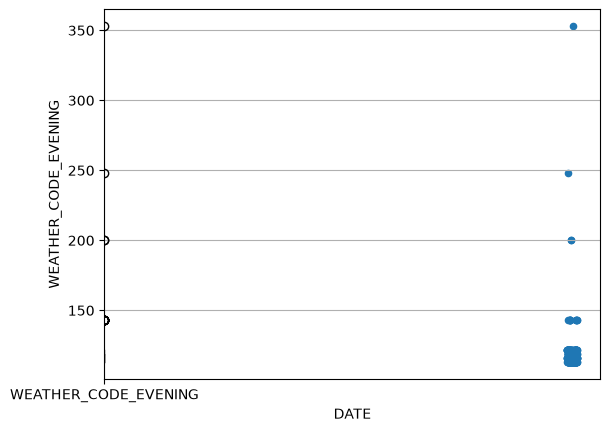

In [49]:
# Analyser la distribution d'une variable numérique

# df2018["DATE"] = pd.to_datetime(df2018["DATE"])
df2018["DATE"] = pd.to_datetime(df2018["DATE"])

# Draw a scatterplot with Date on X-axis and WEATHER_CODE_EVENING on Y-axis (Aussi nommé nuage de points)
df2018.plot.scatter(x="DATE", y="WEATHER_CODE_EVENING")

# Affichage en boîte à moustaches
df2018.boxplot(column="WEATHER_CODE_EVENING")

for i in range(0, 11):                                       # 0 = minimum, 1 à 9 = déciles, 10 = maximum
    print(i / 10, df2018["WEATHER_CODE_EVENING"].quantile(i / 10))

In [50]:
import pandas as pd

# 1. On s'assure que la colonne DATE est bien au bon format
df2018["DATE"] = pd.to_datetime(df2018["DATE"])

# 2. On crée la liste des déciles de 0.0 à 1.0
deciles = [i / 10 for i in range(0, 11)]

# 3. On calcule les quantiles, on convertit en DataFrame pour l'affichage, et on renomme
tableau_deciles = (
    df2018["WEATHER_CODE_EVENING"].quantile(deciles).to_frame()
)
tableau_deciles.columns = ["WEATHER_CODE_EVENING"]

# 4. On affiche le tableau proprement
tableau_deciles


,WEATHER_CODE_EVENING
0.0,113.0
0.1,113.0
0.2,113.0
0.3,113.0
0.4,113.0
0.5,116.0
0.6,116.0
0.7,119.0
0.8,122.0
0.9,122.0


#### Boxplot directly with Pandas

Here you can find [a little help](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.boxplot.html)

In [51]:
# Find a way to draw directly with pandas a boxplot on the column WEATHER_CODE_EVENING

# Pour la neige, on remplace les données manquantes par la "médiane". 
# Comme il ne neige presque jamais en France dans l'année, la valeur du milieu est de 0 mm. 
df2018["TOTAL_SNOW_MM"].fillna(df2018["TOTAL_SNOW_MM"].median(), inplace=True)

# Pour l'indice UV, on utilise aussi la valeur du milieu. 
# Ce qui permet de boucher les trous sans fausser le niveau de rayonnement général du reste de l'année.
df2018["UV_INDEX"].fillna(df2018["UV_INDEX"].median(), inplace=True)


C:\Users\steph\AppData\Local\Temp\ipykernel_2716\576105163.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df2018["TOTAL_SNOW_MM"].fillna(df2018["TOTAL_SNOW_MM"].median(), inplace=True)
C:\Users\steph\AppData\Local\Temp\ipykernel_2716\576105163.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Ser

0      3.0
1      3.0
2      3.0
3      3.0
4      3.0
      ... 
360    1.0
361    1.0
362    1.0
363    1.0
364    1.0
Name: UV_INDEX, Length: 365, dtype: float64

In [52]:
# Remplace les NaN de plusieurs colonnes d'un seul coup
df2018.fillna(
    {
        "TOTAL_SNOW_MM": df2018["TOTAL_SNOW_MM"].median(),
        "UV_INDEX": df2018["UV_INDEX"].median(),
    },
    inplace=True,
)

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,flag
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,41.750,12,8,7,113.0,0.0,3.0,5.1,bad,False
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,87.875,13,12,6,122.0,0.0,3.0,3.3,bad,False
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,91.500,15,13,7,122.0,0.0,3.0,3.3,bad,False
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,90.125,14,12,10,116.0,0.0,3.0,3.3,bad,False
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,62.375,12,10,7,116.0,0.0,3.0,6.9,bad,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2018-12-27,7,2,6,2,6,5,0.0,85,10.000,...,30.750,8,6,3,119.0,0.0,1.0,8.7,very bad,False
361,2018-12-28,7,2,8,2,7,3,0.0,89,8.000,...,18.750,8,4,4,113.0,0.0,1.0,8.7,very bad,False
362,2018-12-29,7,1,6,1,6,4,0.0,94,7.000,...,33.000,8,5,1,116.0,0.0,1.0,8.7,very bad,False
363,2018-12-30,9,4,6,5,9,8,0.1,95,6.000,...,70.375,10,9,7,143.0,0.0,1.0,3.3,very bad,False


#### Deciles

Here you can find [a little help](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html)

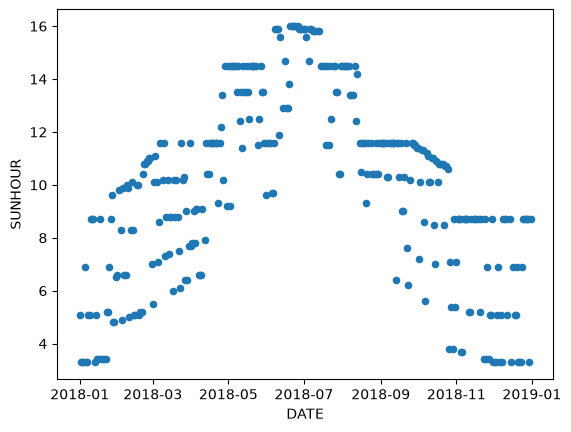

In [53]:
# Find a way to print the 9 deciles + min + max of the column WEATHER_CODE_EVENING with the quantile method of pandas and a loop

# On dessine un graphique à points pour observer les heures de soleil au fil de l'année, ce qui permet de voir si le soleil varie selon les saisons.
df2018.plot.scatter(x="DATE", y="SUNHOUR")

# On écrase proprement la colonne avec la version complétée vers l'arrière.
df2018["SUNHOUR"] = df2018["SUNHOUR"].bfill()



#### Fill values
OK it seems that the most of datas are between 113 and 122. Maybe, we could fill the missing values with Mean or Median, it's up to you to choose. So you need :
- Calculate the mean or the median
- Fill the missing values only for **WEATHER_CODE_EVENING** with the `fillna()` method

When you're OK, remember tu use the `inplace=True` argument, otherwise, your modification will not be stored.

In [54]:
# Calcule la valeur médiane de la colonne.
mean_weather_column = df2018['WEATHER_CODE_EVENING'].median()

# Remplace les NaN et réassigne proprement dans le tableau.
df2018['WEATHER_CODE_EVENING'] = df2018['WEATHER_CODE_EVENING'].fillna(mean_weather_column)

# Compte et affiche le nombre de valeurs pour vérifier.
print(df2018['WEATHER_CODE_EVENING'].value_counts())

WEATHER_CODE_EVENING
113.0    154
116.0    102
122.0     59
119.0     34
143.0     12
200.0      2
248.0      1
353.0      1
Name: count, dtype: int64


In [55]:
# You can use this code to check how many missing values you have :

# 1. Définit le nom de la colonne à analyser.
column_name = 'WEATHER_CODE_EVENING'

# 2. Compte les lignes vides et affiche le total sous forme de phrase.
print("J'ai", df2018[column_name].isna().sum(), "valeurs manquantes dans la colonne", column_name)


J'ai 0 valeurs manquantes dans la colonne WEATHER_CODE_EVENING


### 3.2 - Next columns : TOTAL_SNOW_MM and UV_INDEX

We trust you to choose right values to fill for both columns

In [59]:
# Your code here

# Remplace les lignes vides par 0 dans les colonnes choisies
df2018[["TOTAL_SNOW_MM", "UV_INDEX"]] = df2018[["TOTAL_SNOW_MM", "UV_INDEX"]].fillna(0)

# Compte et affiche le nombre de valeurs vides restantes (doit afficher 0)
print(df2018[["TOTAL_SNOW_MM", "UV_INDEX"]].isna().sum())


TOTAL_SNOW_MM    0
UV_INDEX         0
dtype: int64


### 3.3 - Next column :
SUNHOUR

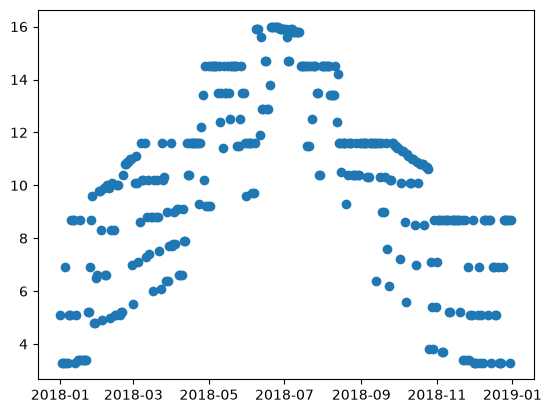

In [60]:
import matplotlib.pyplot as plt  # Importe l'outil pour dessiner les graphiques

# Crée le graphique avec la colonne DATE en X et SUNHOUR en Y
plt.scatter(df2018["DATE"], df2018["SUNHOUR"])
plt.show()  # Affiche le graphique à l'écran

#### Propagation
**It seems this is not a good idea to apply the same value all year long...**

You could use the the `method = 'ffill'` or `'bfill'` argument in `fillna()` to propagate non-null values forward or backward.

In [64]:
# Propage la dernière valeur connue pour remplir les cases vides
df2018["SUNHOUR"] = df2018["SUNHOUR"].ffill()

# Vérifie qu'il n'y a plus aucune valeur vide dans cette colonne
print(df2018["SUNHOUR"].isna().sum())


0


### 3.4 - Column : OPINION
For Opinion, we have not yet idea. So, we can write a new value 'unknown' in this column.

In [63]:
# Your code here

# Remplace toutes les valeurs vides de la colonne par le mot 'unknown'
df2018["OPINION"] = df2018["OPINION"].fillna("unknown")

# Affiche les 5 premières lignes pour vérifier le résultat
print(df2018["OPINION"].head())


0    bad
1    bad
2    bad
3    bad
4    bad
Name: OPINION, dtype: str


## Now, each axis should have 365 non-null values.

In [68]:
df2018.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    365 non-null    datetime64[us]
 1   MAX_TEMPERATURE_C       365 non-null    int64         
 2   MIN_TEMPERATURE_C       365 non-null    int64         
 3   WINDSPEED_MAX_KMH       365 non-null    int64         
 4   TEMPERATURE_MORNING_C   365 non-null    int64         
 5   TEMPERATURE_NOON_C      365 non-null    int64         
 6   TEMPERATURE_EVENING_C   365 non-null    int64         
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64       
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64         
 9   VISIBILITY_AVG_KM       365 non-null    float64       
 10  PRESSURE_MAX_MB         365 non-null    int64         
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64       
 12  HEATINDEX_MAX_C         365 non-null    int64         
 13  D

## 4 - Visualize your modifications
Draw 4 scatterplots with Date on X-axis, and each of the 4 numeric modified columns on Y-axis :
- The original datas will be in blue
- The new data (your datas) in red

It's the moment to use your "flag" column created at the beginning. It'll be easier in seaborn with `hue` argument.

You should get something like this:

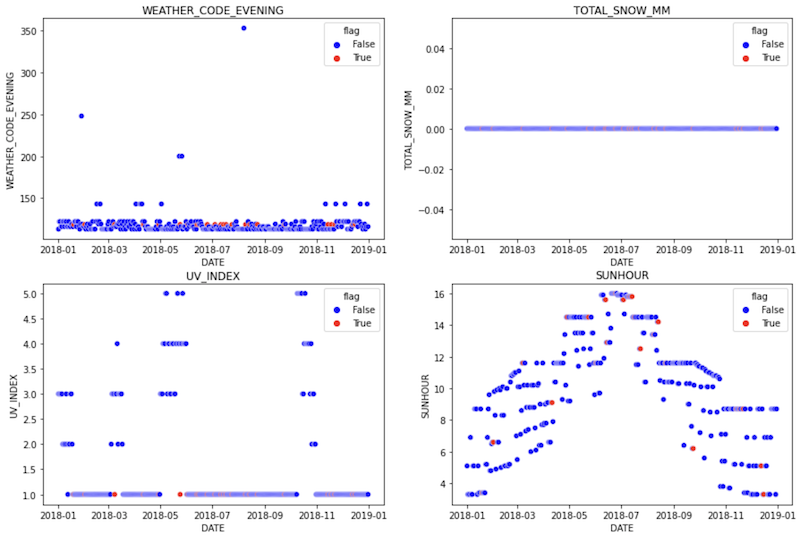

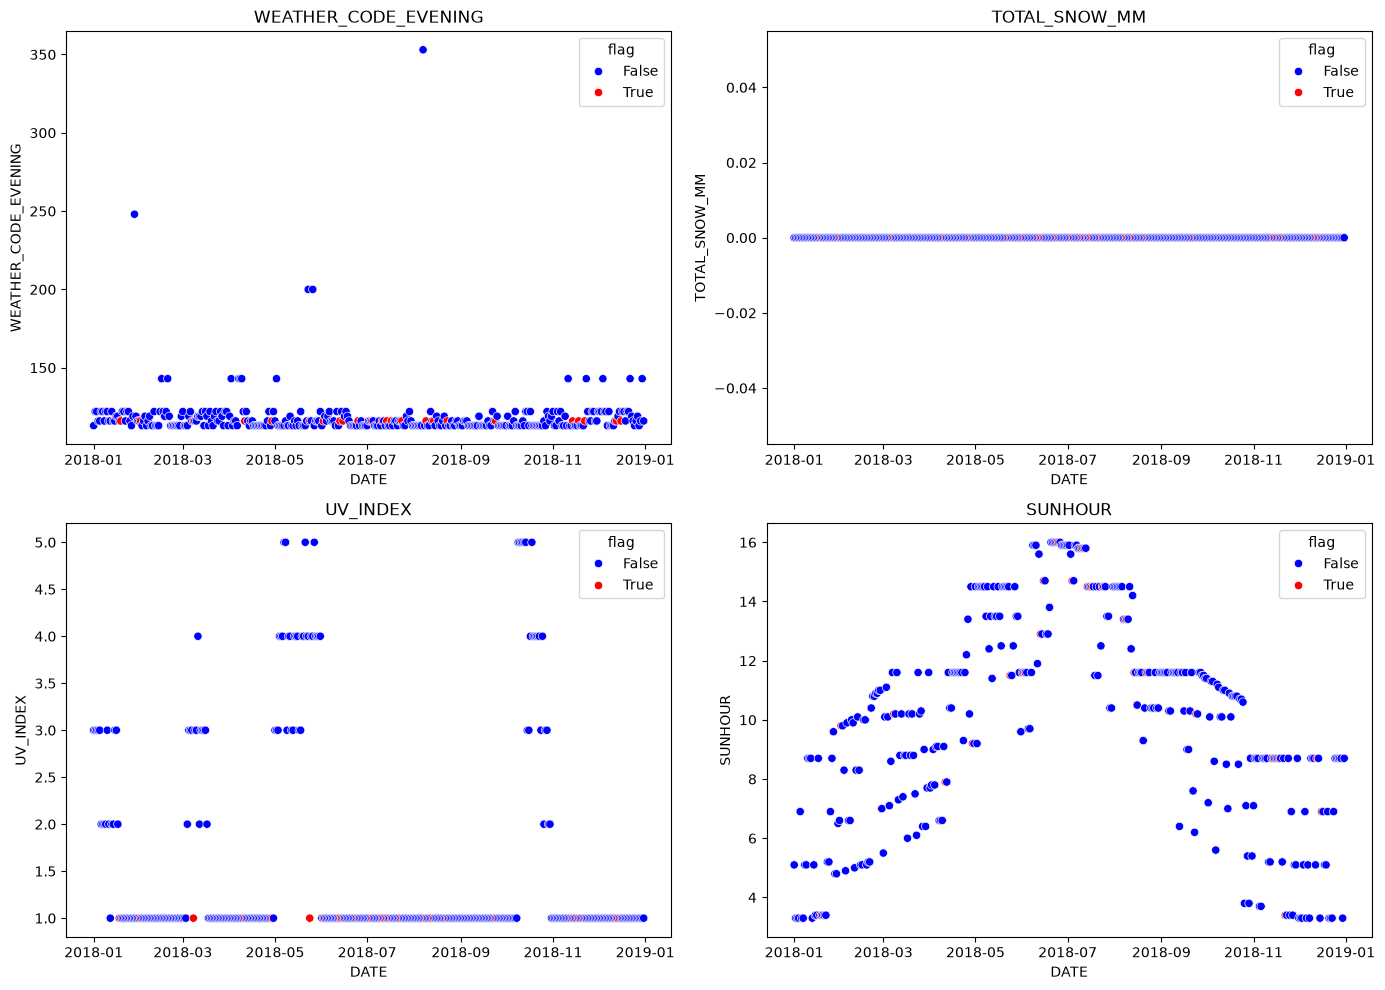

In [66]:
# Your code here

import matplotlib.pyplot as plt
import seaborn as sns

# 1. On prépare une grande zone pour mettre nos 4 graphiques (2 lignes, 2 colonnes)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# CORRECTION : On donne l'adresse exacte de chaque case dans la grille [ligne, colonne]
case_en_haut_gauche = axes[0, 0]  # Ligne 0, Colonne 0
case_en_haut_droite = axes[0, 1]  # Ligne 0, Colonne 1
case_en_bas_gauche  = axes[1, 0]  # Ligne 1, Colonne 0
case_en_bas_droite  = axes[1, 1]  # Ligne 1, Colonne 1

# On définit nos 2 couleurs (Bleu pour l'origine/False, Rouge pour le modifié/True)
mes_couleurs = {False: 'blue', True: 'red'}


# --- GRAPHIQUE 1 : En haut à gauche ---
sns.scatterplot(
    data=df2018, 
    x='DATE', 
    y='WEATHER_CODE_EVENING', 
    hue='flag', 
    palette=mes_couleurs, 
    ax=case_en_haut_gauche
)
case_en_haut_gauche.set_title('WEATHER_CODE_EVENING')


# --- GRAPHIQUE 2 : En haut à droite ---
sns.scatterplot(
    data=df2018, 
    x='DATE', 
    y='TOTAL_SNOW_MM', 
    hue='flag', 
    palette=mes_couleurs, 
    ax=case_en_haut_droite
)
case_en_haut_droite.set_title('TOTAL_SNOW_MM')


# --- GRAPHIQUE 3 : En bas à gauche ---
sns.scatterplot(
    data=df2018, 
    x='DATE', 
    y='UV_INDEX', 
    hue='flag', 
    palette=mes_couleurs, 
    ax=case_en_bas_gauche
)
case_en_bas_gauche.set_title('UV_INDEX')


# --- GRAPHIQUE 4 : En bas à droite ---
sns.scatterplot(
    data=df2018, 
    x='DATE', 
    y='SUNHOUR', 
    hue='flag', 
    palette=mes_couleurs, 
    ax=case_en_bas_droite
)
case_en_bas_droite.set_title('SUNHOUR')


# 2. On ajuste automatiquement l'espace pour éviter les chevauchements
plt.tight_layout()

# 3. On affiche la grille finale
plt.show()
